Superstore Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("archive (1).zip")

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


Data Cleaning

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [5]:
df['Postal Code']= df['Postal Code'].fillna(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9800 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [7]:
df['Postal Code'] = df ['Postal Code'].astype(int)

In [8]:
df['Order Date']=pd.to_datetime(df['Order Date'])
df['Ship Date']=pd.to_datetime(df['Ship Date'])

In [9]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9800.000000,9800.000000
mean,4900.500000,55211.280918,230.769059
std,2829.160653,32076.677954,626.651875
min,1.000000,0.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,57551.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [10]:
df.duplicated().sum()

0

In [11]:
type_customer = df['Segment'].unique()

In [12]:
print(type_customer)

['Consumer' 'Corporate' 'Home Office']


In [13]:
number_customer = df['Segment'].value_counts()

In [14]:
print(number_customer)

Consumer       5101
Corporate      2953
Home Office    1746
Name: Segment, dtype: int64


Text(0.5, 1.0, 'Distribution of Customers')

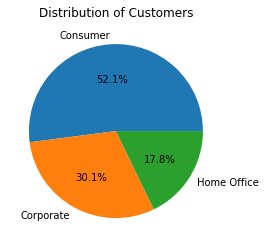

In [15]:
plt.pie(number_customer,autopct="%1.1f%%",labels=type_customer)
plt.title('Distribution of Customers')

Sales of different types of customers

In [16]:
sales_per_category = df.groupby('Segment')['Sales'].sum()

print(sales_per_category)

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64


Text(0.5, 1.0, 'Sales per Customer Category')

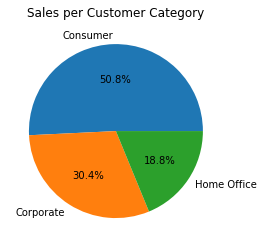

In [17]:
plt.pie(sales_per_category,autopct="%1.1f%%",labels=type_customer)
plt.title('Sales per Customer Category')

Which customer orders the most?

In [18]:
customer_order = df.groupby(['Customer ID','Customer Name','Segment'])['Order ID'].count().reset_index()
customer_order.rename(columns={'Order ID':'Total Orders'},inplace=True)
repeat_cust = customer_order[customer_order['Total Orders'] >= 1]
repeat_customers_sorted = repeat_cust.sort_values(by='Total Orders', ascending=False)

print(repeat_customers_sorted.head(12).reset_index(drop=True))

   Customer ID        Customer Name      Segment  Total Orders
0     WB-21850        William Brown     Consumer            35
1     PP-18955           Paul Prost  Home Office            34
2     MA-17560         Matt Abelman  Home Office            34
3     JL-15835             John Lee     Consumer            33
4     CK-12205  Chloris Kastensmidt     Consumer            32
5     SV-20365          Seth Vernon     Consumer            32
6     JD-15895     Jonathan Doherty    Corporate            32
7     AP-10915       Arthur Prichep     Consumer            31
8     ZC-21910     Zuschuss Carroll     Consumer            31
9     EP-13915           Emily Phan     Consumer            31
10    LC-16870        Lena Cacioppo     Consumer            30
11    Dp-13240          Dean percer  Home Office            29


Which customers bring the most sales?

In [19]:
customer_sales = df.groupby(['Customer ID', 'Customer Name', 'Segment'])['Sales'].sum().reset_index()
top_spenders = customer_sales.sort_values(by='Sales', ascending=False)
print(top_spenders.head(10).reset_index(drop=True))

  Customer ID       Customer Name      Segment      Sales
0    SM-20320         Sean Miller  Home Office  25043.050
1    TC-20980        Tamara Chand    Corporate  19052.218
2    RB-19360        Raymond Buch     Consumer  15117.339
3    TA-21385        Tom Ashbrook  Home Office  14595.620
4    AB-10105       Adrian Barton     Consumer  14473.571
5    KL-16645        Ken Lonsdale     Consumer  14175.229
6    SC-20095        Sanjit Chand     Consumer  14142.334
7    HL-15040        Hunter Lopez     Consumer  12873.298
8    SE-20110        Sanjit Engle     Consumer  12209.438
9    CC-12370  Christopher Conant     Consumer  12129.072


Method of Shipping

In [20]:
type_ship = df['Ship Mode'].unique()
print(type_ship)

['Second Class' 'Standard Class' 'First Class' 'Same Day']


In [21]:
ship_mode = df['Ship Mode'].value_counts().reset_index()
ship_mode = ship_mode.rename(columns={'index':'Mode_of_Shipment', 'Ship Mode': 'Use Frequency'})


In [22]:
ship_mode

,Mode_of_Shipment,Use Frequency
0,Standard Class,5859
1,Second Class,1902
2,First Class,1501
3,Same Day,538


Text(0.5, 1.0, 'Popular Mode Of Shipment')

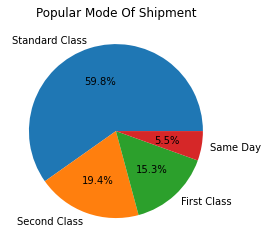

In [23]:
plt.pie(ship_mode['Use Frequency'], labels=ship_mode['Mode_of_Shipment'], autopct='%1.1f%%')

# Set the title of the pie chart
plt.title('Popular Mode Of Shipment')

Top 10 customers from different states and cities

In [24]:
state = df['State'].value_counts().reset_index()
state = state.rename(columns={'index':'State', 'State':'Number_of_customers'})
print(state.head(10))

            State  Number_of_customers
0      California                 1946
1        New York                 1097
2           Texas                  973
3    Pennsylvania                  582
4      Washington                  504
5        Illinois                  483
6            Ohio                  454
7         Florida                  373
8        Michigan                  253
9  North Carolina                  247


In [25]:
city=df['City'].value_counts().reset_index()
city= city.rename(columns={'index':'City','City':'Number of customers'})
print(city.head(10))

            City  Number of customers
0  New York City                  891
1    Los Angeles                  728
2   Philadelphia                  532
3  San Francisco                  500
4        Seattle                  426
5        Houston                  374
6        Chicago                  308
7       Columbus                  221
8      San Diego                  170
9    Springfield                  161


Highest sales in top 10 states and cities

In [26]:
states_sales= df.groupby('State')['Sales'].sum().reset_index()
top_state_sales =states_sales.sort_values(by='Sales',ascending=False)
print(top_state_sales.head(10).reset_index(drop=True))

          State        Sales
0    California  446306.4635
1      New York  306361.1470
2         Texas  168572.5322
3    Washington  135206.8500
4  Pennsylvania  116276.6500
5       Florida   88436.5320
6      Illinois   79236.5170
7      Michigan   76136.0740
8          Ohio   75130.3500
9      Virginia   70636.7200


In [27]:
city_sales = df.groupby('City')['Sales'].sum().reset_index()
top_city_sales = city_sales.sort_values(by='Sales',ascending = False)
print(top_city_sales.head(10).reset_index(drop=True))

            City        Sales
0  New York City  252462.5470
1    Los Angeles  173420.1810
2        Seattle  116106.3220
3  San Francisco  109041.1200
4   Philadelphia  108841.7490
5        Houston   63956.1428
6        Chicago   47820.1330
7      San Diego   47521.0290
8   Jacksonville   44713.1830
9        Detroit   42446.9440


Categories and Subcategories

In [28]:
df['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [29]:
df['Sub-Category'].unique()

array(['Bookcases', 'Chairs', 'Labels', 'Tables', 'Storage',
       'Furnishings', 'Art', 'Phones', 'Binders', 'Appliances', 'Paper',
       'Accessories', 'Envelopes', 'Fasteners', 'Supplies', 'Machines',
       'Copiers'], dtype=object)

In [30]:
subcategory_count = df.groupby('Category')['Sub-Category'].nunique().reset_index()
print(subcategory_count)

          Category  Sub-Category
0        Furniture             4
1  Office Supplies             9
2       Technology             4


In [31]:
category_sales = df.groupby('Category')['Sales'].sum().reset_index()
print(category_sales)

          Category        Sales
0        Furniture  728658.5757
1  Office Supplies  705422.3340
2       Technology  827455.8730


Text(0.5, 1.0, 'Top Product Categories Based on Sales')

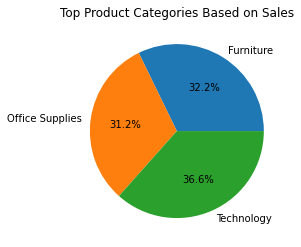

In [32]:
plt.pie(category_sales['Sales'],labels=category_sales['Category'],autopct='%1.1f%%')
plt.title('Top Product Categories Based on Sales')

In [33]:
sub_category_sales = df.groupby('Sub-Category')['Sales'].sum().reset_index()
top_product_subcategory = sub_category_sales.sort_values(by='Sales', ascending=False) 
print(top_product_subcategory.reset_index(drop=True))

   Sub-Category        Sales
0        Phones  327782.4480
1        Chairs  322822.7310
2       Storage  219343.3920
3        Tables  202810.6280
4       Binders  200028.7850
5      Machines  189238.6310
6   Accessories  164186.7000
7       Copiers  146248.0940
8     Bookcases  113813.1987
9    Appliances  104618.4030
10  Furnishings   89212.0180
11        Paper   76828.3040
12     Supplies   46420.3080
13          Art   26705.4100
14    Envelopes   16128.0460
15       Labels   12347.7260
16    Fasteners    3001.9600


Text(0, 0.5, 'Total Sales')

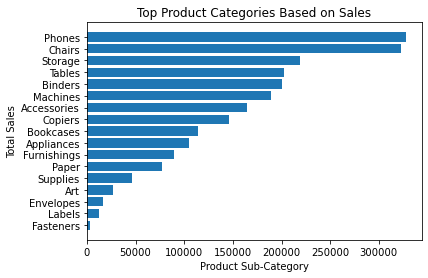

In [34]:
top_product_subcategory = top_product_subcategory.sort_values(by='Sales', ascending=True)

plt.barh(top_product_subcategory['Sub-Category'],top_product_subcategory['Sales'])
plt.title('Top Product Categories Based on Sales')
plt.xlabel('Product Sub-Category')
plt.ylabel('Total Sales')



Yearly Sales

In [35]:
yearly_sales = df.groupby(df['Order Date'].dt.year)['Sales'].sum()
yearly_sales = yearly_sales.reset_index()
yearly_sales = yearly_sales.rename(columns={'Order Date': 'Year', 'Sales':'Total Sales'})
print(yearly_sales)

   Year  Total Sales
0  2015  479856.2081
1  2016  459436.0054
2  2017  600192.5500
3  2018  722052.0192


(array([2014. , 2014.5, 2015. , 2015.5, 2016. , 2016.5, 2017. , 2017.5,
        2018. , 2018.5, 2019. ]),
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

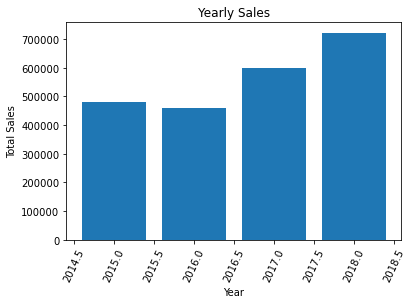

In [36]:
plt.bar(yearly_sales['Year'], yearly_sales['Total Sales'])

# Labels
plt.title('Yearly Sales')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=65)


Text(0.5, 1.0, 'Total Sales by Year')

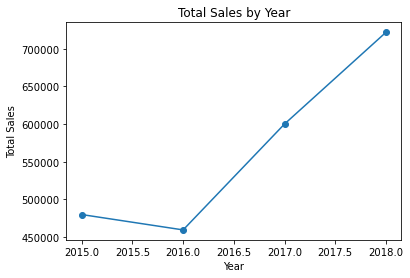

In [37]:
plt.plot(yearly_sales['Year'], yearly_sales['Total Sales'], marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.title('Total Sales by Year')

Quarterly Sales of 2018

In [38]:
year_sales = df[df['Order Date'].dt.year == 2018]
quarterly_sales = year_sales.resample('Q', on='Order Date')['Sales'].sum()
quarterly_sales = quarterly_sales.reset_index()
quarterly_sales = quarterly_sales.rename(columns={'Order Date': 'Quarter', 'Sales':'Total Sales'})
print("Quarterly Sales for 2018:")
print(quarterly_sales)

Quarterly Sales for 2018:
     Quarter  Total Sales
0 2018-03-31  183444.5482
1 2018-06-30  125644.5095
2 2018-09-30  202504.9235
3 2018-12-31  210458.0380


Text(0.5, 1.0, 'Total Sales by Year')

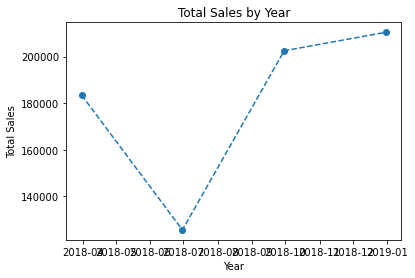

In [39]:
plt.plot(quarterly_sales['Quarter'], quarterly_sales['Total Sales'], marker='o', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.title('Total Sales by Year')


Monthly Sales of 2018

In [40]:
year_sales = df[df['Order Date'].dt.year==2018]
monthly_sales = year_sales.resample('M',on='Order Date')['Sales'].sum()
monthly_sales = monthly_sales.reset_index()
monthly_sales = monthly_sales.rename(columns={'Order Date':'Month', 'Sales':'Total Montly Sales'})

print("Monthly Sales for 2018:")
print(monthly_sales)

Monthly Sales for 2018:
        Month  Total Montly Sales
0  2018-01-31          59767.0910
1  2018-02-28          48928.8334
2  2018-03-31          74748.6238
3  2018-04-30          37849.2156
4  2018-05-31          40882.4464
5  2018-06-30          46912.8475
6  2018-07-31          53942.7755
7  2018-08-31          75408.7840
8  2018-09-30          73153.3640
9  2018-10-31          65501.1622
10 2018-11-30          87997.6400
11 2018-12-31          56959.2358


Text(0.5, 1.0, 'Total Sales by Month')

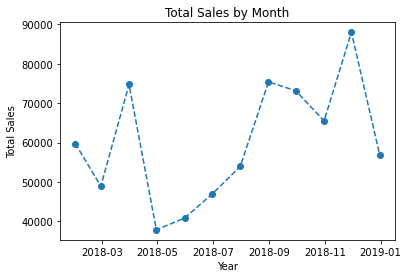

In [41]:
plt.plot(monthly_sales['Month'], monthly_sales['Total Montly Sales'], marker='o', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.title('Total Sales by Month')
